First five rows:
                           name  year  selling_price  km_driven    fuel  \
0        Maruti Swift Dzire VDI  2014         450000     145500  Diesel   
1  Skoda Rapid 1.5 TDI Ambition  2014         370000     120000  Diesel   
2      Honda City 2017-2020 EXi  2006         158000     140000  Petrol   
3     Hyundai i20 Sportz Diesel  2010         225000     127000  Diesel   
4        Maruti Swift VXI BSIII  2007         130000     120000  Petrol   

  seller_type transmission         owner     mileage   engine   max_power  \
0  Individual       Manual   First Owner   23.4 kmpl  1248 CC      74 bhp   
1  Individual       Manual  Second Owner  21.14 kmpl  1498 CC  103.52 bhp   
2  Individual       Manual   Third Owner   17.7 kmpl  1497 CC      78 bhp   
3  Individual       Manual   First Owner   23.0 kmpl  1396 CC      90 bhp   
4  Individual       Manual   First Owner   16.1 kmpl  1298 CC    88.2 bhp   

                     torque  seats  
0            190Nm@ 2000rpm    5

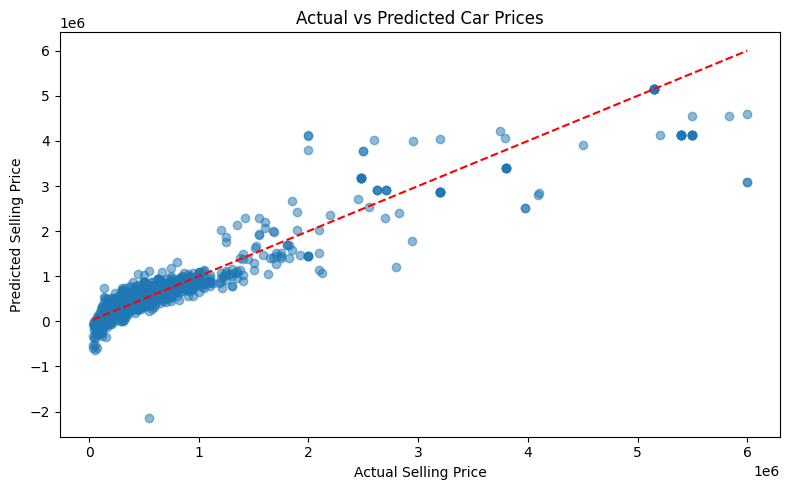


Model Intercept: -84094674.18027538

Feature Coefficients:
                     Feature   Coefficient
                        year  4.191782e+04
                   km_driven -9.538765e-01
                      engine  6.767769e+01
                   max_power  6.348932e+03
                       seats -2.760215e+03
                 fuel_Diesel  1.468195e+05
                    fuel_LPG  1.800257e+05
                 fuel_Petrol  5.944965e+04
         transmission_Manual -1.016717e+05
      seller_type_Individual -4.686954e+04
seller_type_Trustmark Dealer -6.716784e+04
  owner_Fourth & Above Owner -1.341430e+04
          owner_Second Owner -6.484159e+04
        owner_Test Drive Car  2.925593e+06
           owner_Third Owner -3.729668e+04
                 brand_Ashok  9.799493e-06
                  brand_Audi  5.922984e+05
                   brand_BMW  2.129412e+06
             brand_Chevrolet -4.322719e+05
                brand_Daewoo  1.121540e+05
                brand_Datsun -4.82004

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


df = pd.read_csv("/content/Car details v3.csv")

print("First five rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())


df["engine"] = pd.to_numeric(
    df["engine"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

df["max_power"] = pd.to_numeric(
    df["max_power"].astype(str).str.extract(r"(\d+\.?\d*)", expand=False),
    errors="coerce"
)

df["brand"] = df["name"].str.split().str[0]


features = [
    "year",
    "km_driven",
    "engine",
    "max_power",
    "seats",
    "fuel",
    "transmission",
    "seller_type",
    "owner",
    "brand"
]

target = "selling_price"


data = df[features + [target]].dropna().copy()


data = pd.get_dummies(
    data,
    columns=["fuel", "transmission", "seller_type", "owner", "brand"],
    drop_first=True,
    dtype=int
)

print("\nCleaned Dataset:")
print(data.head())


X = data.drop("selling_price", axis=1)
y = data["selling_price"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")


y_pred = model.predict(X_test)

print("\nActual vs Predicted Prices:")
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))



mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)



plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.tight_layout()
plt.show()


print("\nModel Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nFeature Coefficients:")
print(coefficients.to_string(index=False))
